In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

path = "./"  # preencha com o caminho da pasta


In [2]:
nomes_csv = sorted(f for f in os.listdir(path) if f.lower().endswith(".csv"))

print(f"{len(nomes_csv)} arquivos CSV encontrados")
for nome in nomes_csv:
    print(nome)

colunas = {
    "tempo_de_integracao": "TI",
    "numero_total_de_passos_realizados_nst": "NST",
    "numero_de_avaliacoes_funcao_nfe": "NFE",
    "numero_avaliacoes_jacobiana_nje": "NJE",
}

instancias = []
for nome in nomes_csv:
    metodo, seed, solver, geracoes, hora = nome[:-4].split("_")
    df = pd.read_csv(os.path.join(path, nome)).rename(columns=colunas)
    instancias.append({
        "arquivo": nome,
        "metodo": metodo,
        "seed": int(seed),
        "solver": solver,
        "geracoes": int(geracoes),
        "hora": int(hora[0:2]),
        "minuto": int(hora[2:4]),
        "segundo": int(hora[4:6]),
        "ti": df["TI"].to_numpy(),
        "nst": df["NST"].to_numpy(),
        "nfe": df["NFE"].to_numpy(),
        "nje": df["NJE"].to_numpy(),
    })


4 arquivos CSV encontrados
DE_0_ODEINT_32_014524.csv
DE_1_ODEINT_32_015314.csv
DE_2_ODEINT_32_020037.csv
DE_3_ODEINT_32_020727.csv


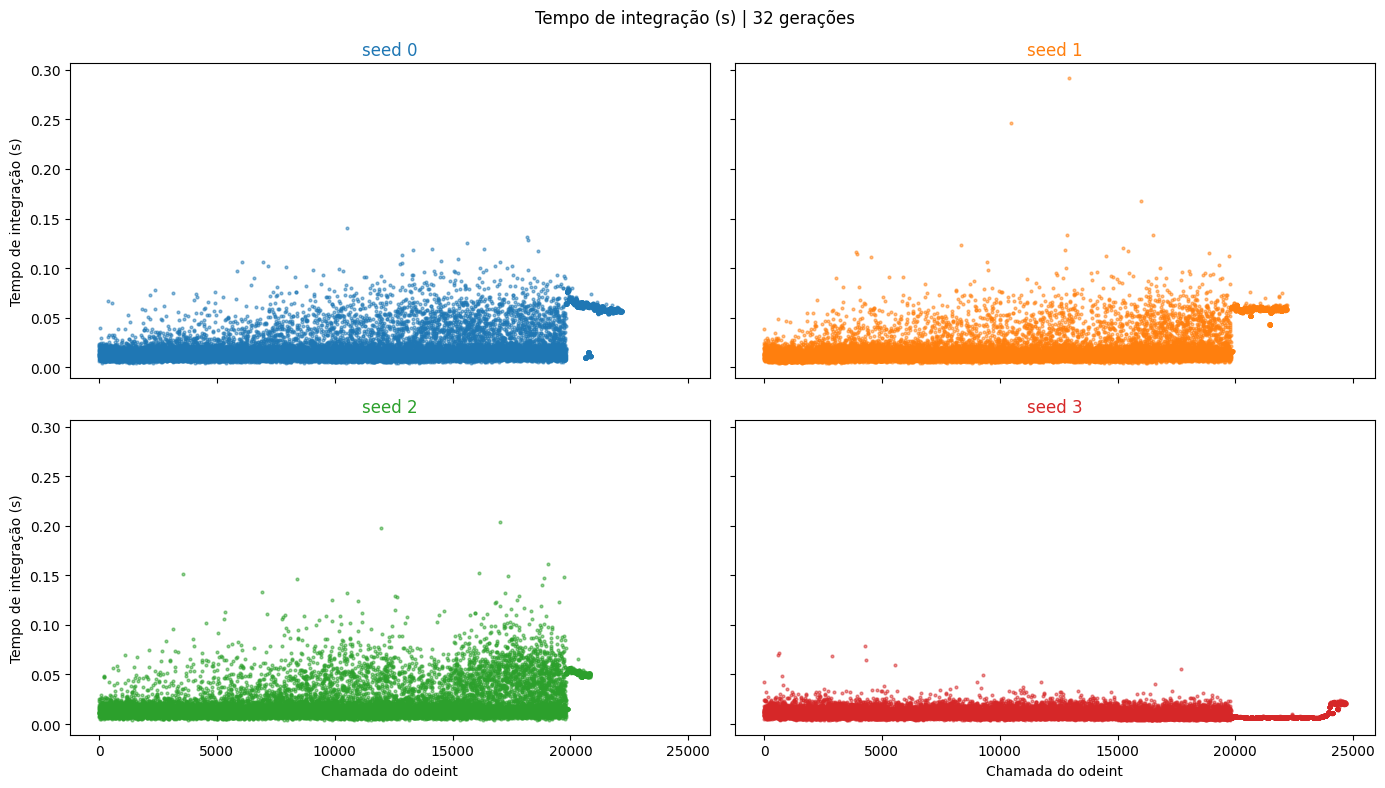

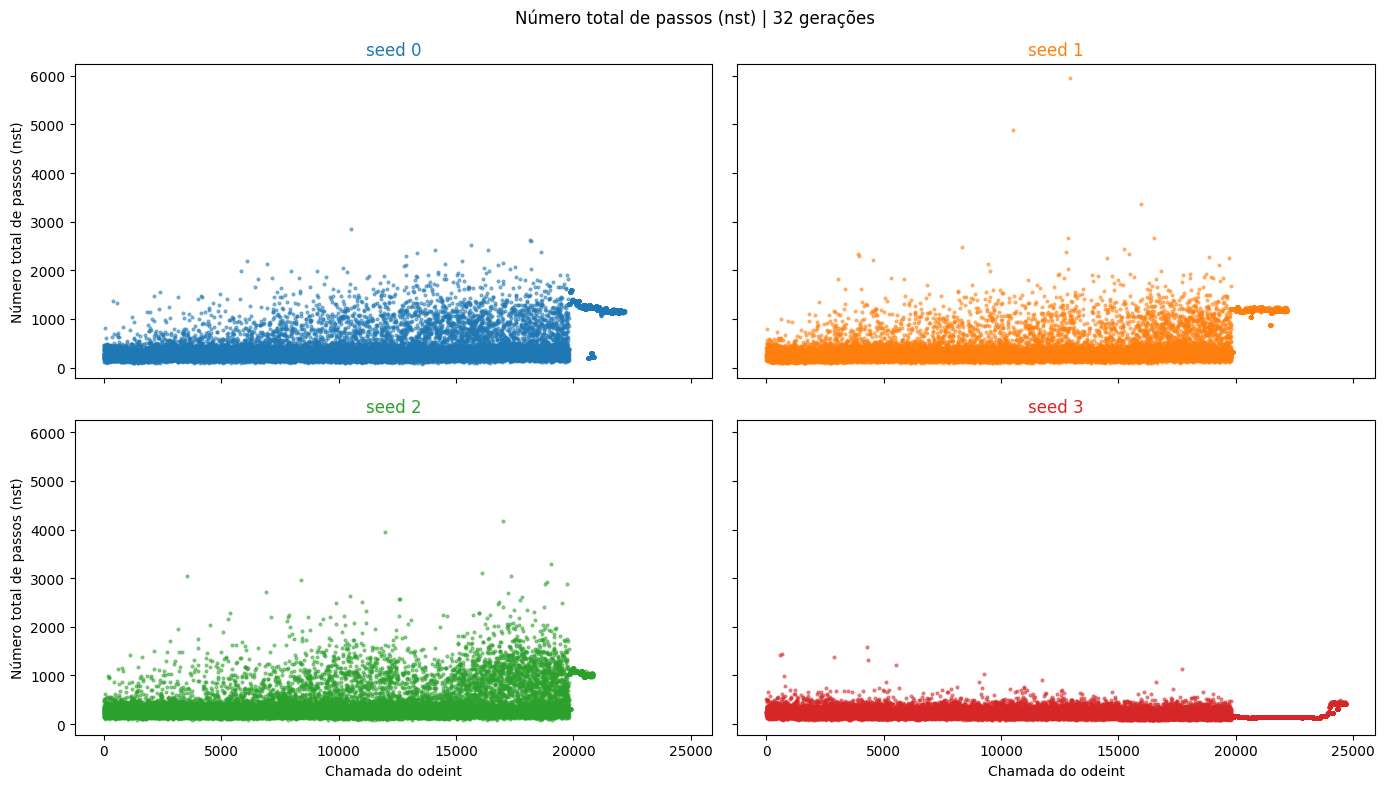

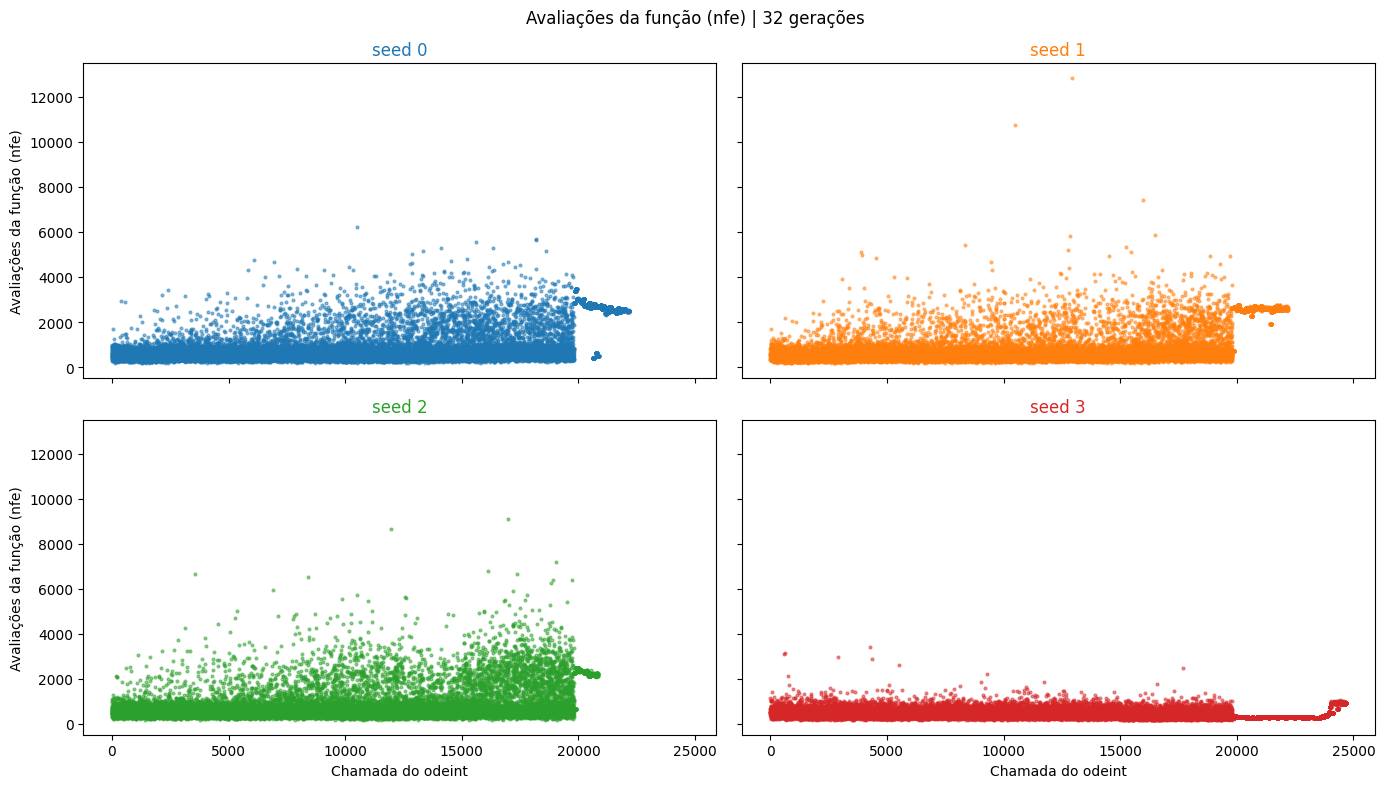

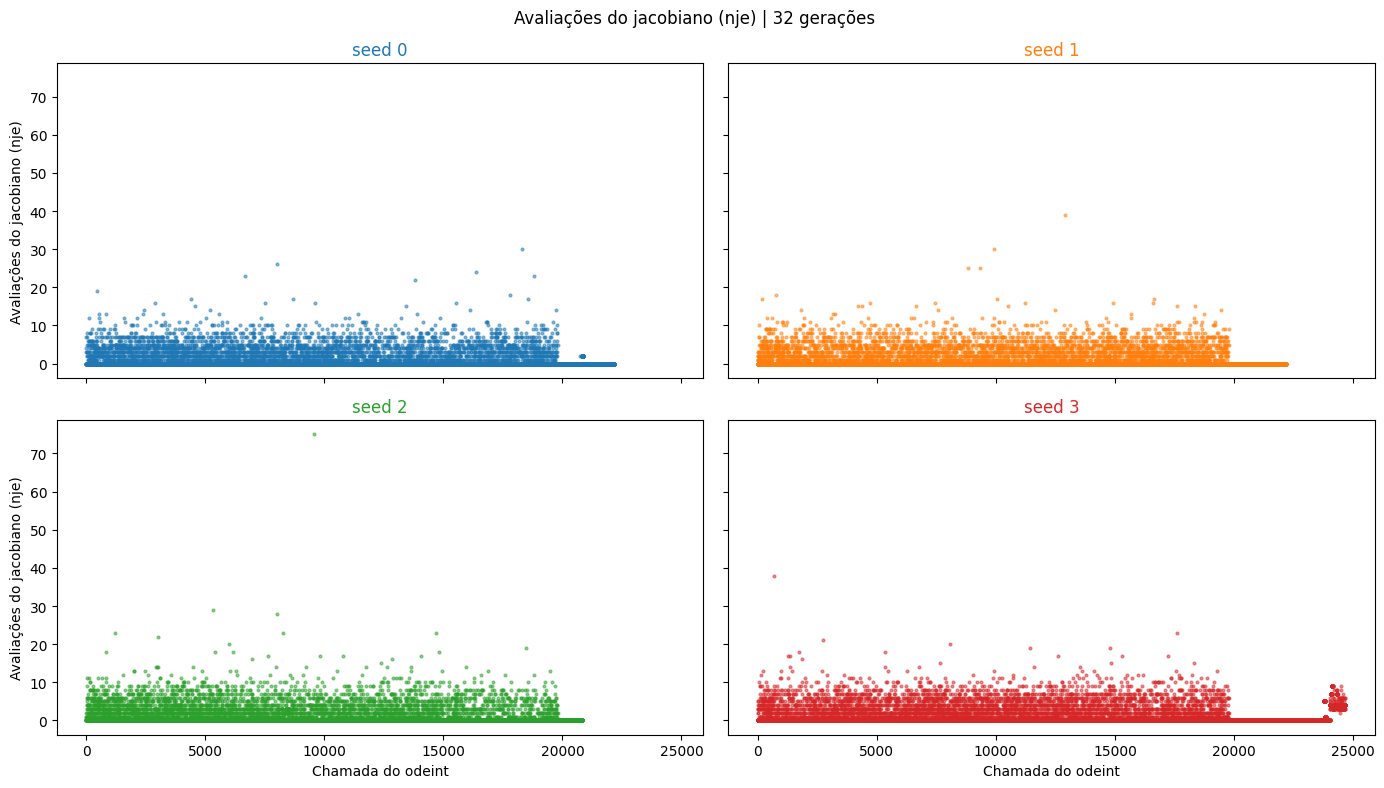

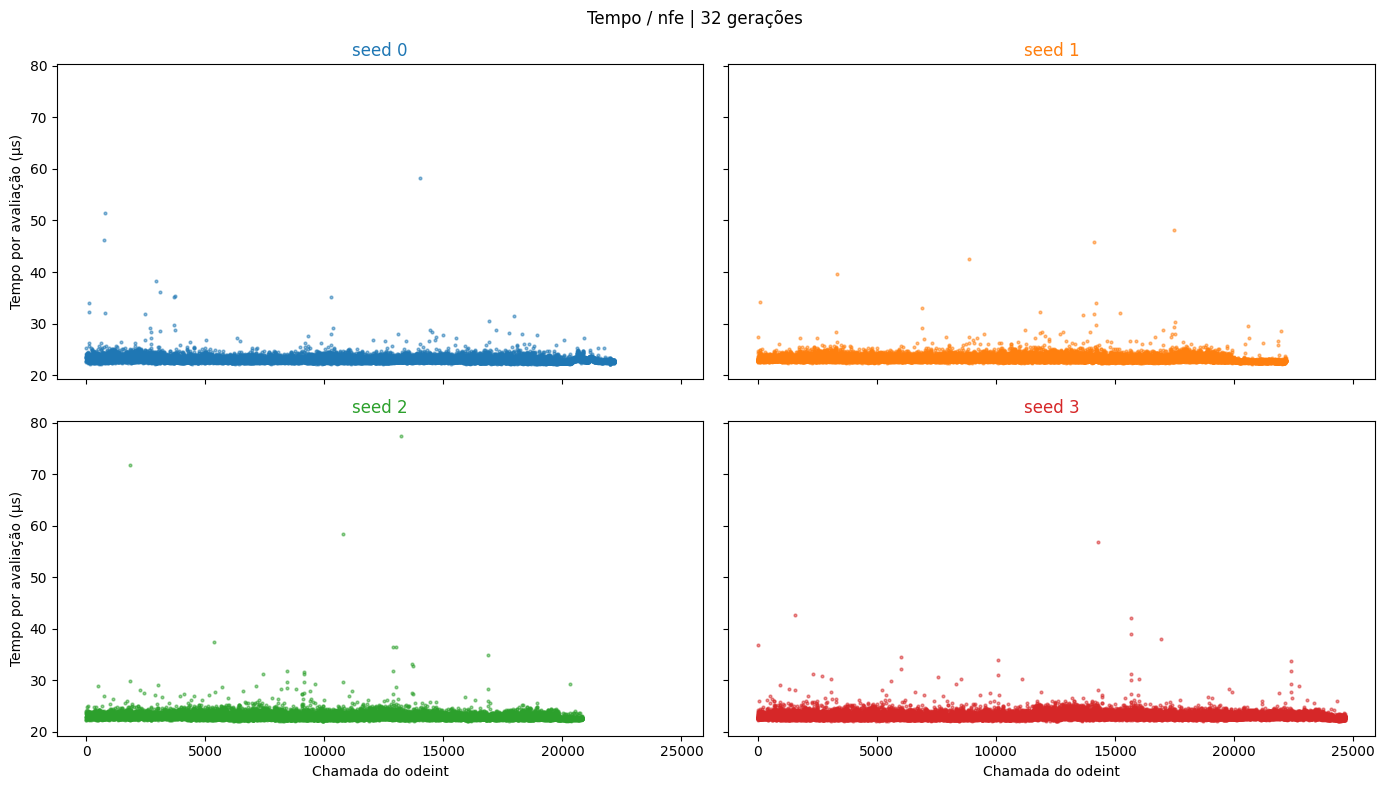

In [3]:
rotulos = {
    "ti": "Tempo de integração (s)",
    "nst": "Número total de passos (nst)",
    "nfe": "Avaliações da função (nfe)",
    "nje": "Avaliações do jacobiano (nje)",
}

seeds = sorted({i["seed"] for i in instancias})
por_seed = {s: next(i for i in instancias if i["seed"] == s) for s in seeds}
cores = {s: f"C{k}" for k, s in enumerate(seeds)}
geracoes = por_seed[seeds[0]]["geracoes"]

# Gráficos de ti, nst, nfe e nje
for chave, rotulo in rotulos.items():
    fig, eixos = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)

    for ax, s in zip(eixos.flat, seeds):
        y = por_seed[s][chave]
        x = np.arange(len(y)) + 1
        ax.scatter(x, y, s=4, alpha=0.5, color=cores[s])
        ax.set_title(f"seed {s}", color=cores[s])

    for ax in eixos[1]:
        ax.set_xlabel("Chamada do odeint")
    for ax in eixos[:, 0]:
        ax.set_ylabel(rotulo)

    fig.suptitle(f"{rotulo} | {geracoes} gerações")
    fig.tight_layout()
    plt.show()

# Gráfico de tempo por nfe
fig, eixos = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)

for ax, s in zip(eixos.flat, seeds):
    ti_por_nfe_us = por_seed[s]["ti"] / por_seed[s]["nfe"] * 1e6
    x = np.arange(len(ti_por_nfe_us)) + 1
    ax.scatter(x, ti_por_nfe_us, s=4, alpha=0.5, color=cores[s])
    ax.set_title(f"seed {s}", color=cores[s])

for ax in eixos[1]:
    ax.set_xlabel("Chamada do odeint")
for ax in eixos[:, 0]:
    ax.set_ylabel("Tempo por avaliação (µs)")

fig.suptitle(f"Tempo / nfe | {geracoes} gerações")
fig.tight_layout()
plt.show()